In [1]:
import numpy as np 
import pandas as pd

In [5]:
titanic = pd.read_csv("titanic.csv", usecols= ["Cabin", "Ticket", "Survived"])
titanic.head()

,Survived,Ticket,Cabin
0,0,A/5 21171,NaN
1,1,PC 17599,C85
2,1,STON/O2. 3101282,NaN
3,1,113803,C123
4,0,373450,NaN


<Axes: xlabel='Survived'>

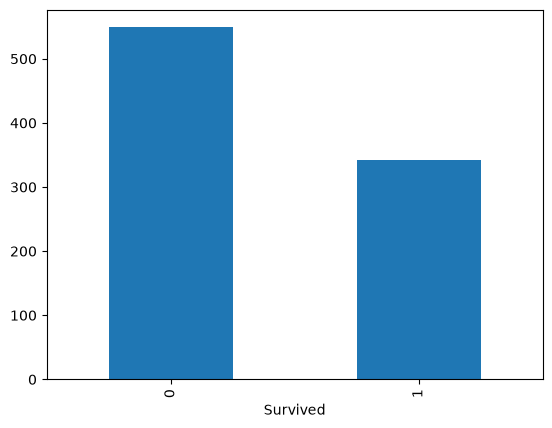

In [7]:
titanic["Survived"].value_counts().plot.bar()

# Working With Date and Time

In [8]:
date = pd.read_csv("orders.csv")
time = pd.read_csv("messages.csv")

### A. DATE

In [16]:
date.head()

,date,product_id,city_id,orders
0,2019-12-10,5628,25,3
1,2018-08-15,3646,14,157
2,2018-10-23,1859,25,1
3,2019-08-17,7292,25,1
4,2019-01-06,4344,25,3


In [11]:
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        1000 non-null   object
 1   product_id  1000 non-null   int64 
 2   city_id     1000 non-null   int64 
 3   orders      1000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 31.4+ KB


In [13]:
date.shape

(1000, 4)

In [15]:
date.describe()

,product_id,city_id,orders
count,1000.000000,1000.000000,1000.000000
mean,3826.379000,16.371000,17.497000
std,2217.585914,8.554211,57.357841
min,5.000000,0.000000,1.000000
25%,1935.000000,13.000000,1.000000
50%,3810.000000,16.000000,4.000000
75%,5778.000000,25.000000,12.000000
max,7585.000000,30.000000,1004.000000


In [17]:
# So the date column Is of type object. Now we need to change the data type of that column to work on it.

date["date"] = pd.to_datetime(date["date"])

In [19]:
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1000 non-null   datetime64[ns]
 1   product_id  1000 non-null   int64         
 2   city_id     1000 non-null   int64         
 3   orders      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 31.4 KB


### 1. Extract Year

In [21]:
date["date_year"] = date["date"].dt.year
date.head()

,date,product_id,city_id,orders,date_year
0,2019-12-10,5628,25,3,2019
1,2018-08-15,3646,14,157,2018
2,2018-10-23,1859,25,1,2018
3,2019-08-17,7292,25,1,2019
4,2019-01-06,4344,25,3,2019


### 2. Extract Month

In [22]:
date["date_month"] = date["date"].dt.month
date.head()

,date,product_id,city_id,orders,date_year,date_month
0,2019-12-10,5628,25,3,2019,12
1,2018-08-15,3646,14,157,2018,8
2,2018-10-23,1859,25,1,2018,10
3,2019-08-17,7292,25,1,2019,8
4,2019-01-06,4344,25,3,2019,1


### 3. Month Name

In [23]:
date["date_month_name"] = date["date"].dt.month_name()
date.head()

,date,product_id,city_id,orders,date_year,date_month,date_month_name
0,2019-12-10,5628,25,3,2019,12,December
1,2018-08-15,3646,14,157,2018,8,August
2,2018-10-23,1859,25,1,2018,10,October
3,2019-08-17,7292,25,1,2019,8,August
4,2019-01-06,4344,25,3,2019,1,January


### 4. Extract Days

In [24]:
date["date_day"] = date["date"].dt.day
date.head()

,date,product_id,city_id,orders,date_year,date_month,date_month_name,date_day
0,2019-12-10,5628,25,3,2019,12,December,10
1,2018-08-15,3646,14,157,2018,8,August,15
2,2018-10-23,1859,25,1,2018,10,October,23
3,2019-08-17,7292,25,1,2019,8,August,17
4,2019-01-06,4344,25,3,2019,1,January,6


### 5. Day Name

In [27]:
date["date_day_name"] = date["date"].dt.day_name()
date.head()

,date,product_id,city_id,orders,date_year,date_month,date_month_name,date_day,date_day_name
0,2019-12-10,5628,25,3,2019,12,December,10,Tuesday
1,2018-08-15,3646,14,157,2018,8,August,15,Wednesday
2,2018-10-23,1859,25,1,2018,10,October,23,Tuesday
3,2019-08-17,7292,25,1,2019,8,August,17,Saturday
4,2019-01-06,4344,25,3,2019,1,January,6,Sunday


### 6. Week

In [34]:
date["date_week"] = date["date"].dt.isocalendar().week
date.head()

,date,product_id,city_id,orders,date_year,date_month,date_month_name,date_day,date_day_name,date_week,date_quarter
0,2019-12-10,5628,25,3,2019,12,December,10,Tuesday,50,4
1,2018-08-15,3646,14,157,2018,8,August,15,Wednesday,33,3
2,2018-10-23,1859,25,1,2018,10,October,23,Tuesday,43,4
3,2019-08-17,7292,25,1,2019,8,August,17,Saturday,33,3
4,2019-01-06,4344,25,3,2019,1,January,6,Sunday,1,1


### 7. Extract Quarter

In [36]:
date["date_quarter"] = date["date"].dt.quarter
date.drop(columns= ["product_id", "city_id", "orders"]).head()

,date,date_year,date_month,date_month_name,date_day,date_day_name,date_week,date_quarter
0,2019-12-10,2019,12,December,10,Tuesday,50,4
1,2018-08-15,2018,8,August,15,Wednesday,33,3
2,2018-10-23,2018,10,October,23,Tuesday,43,4
3,2019-08-17,2019,8,August,17,Saturday,33,3
4,2019-01-06,2019,1,January,6,Sunday,1,1


### 8. Extract Elapsed time between two Dates

In [40]:
import datetime

# This will check date and time of today
today = datetime.datetime.today() 

today

datetime.datetime(2026, 10, 17, 16, 54, 49, 487187)

In [41]:
today - date["date"]

0     2503 days 16:54:49.487187
1     2985 days 16:54:49.487187
2     2916 days 16:54:49.487187
3     2618 days 16:54:49.487187
4     2841 days 16:54:49.487187
                 ...           
995   2931 days 16:54:49.487187
996   2872 days 16:54:49.487187
997   2720 days 16:54:49.487187
998   2785 days 16:54:49.487187
999   2559 days 16:54:49.487187
Name: date, Length: 1000, dtype: timedelta64[ns]

In [42]:
date["date"].head()

0   2019-12-10
1   2018-08-15
2   2018-10-23
3   2019-08-17
4   2019-01-06
Name: date, dtype: datetime64[ns]

In [43]:
(today - date["date"]).dt.days

0      2503
1      2985
2      2916
3      2618
4      2841
       ... 
995    2931
996    2872
997    2720
998    2785
999    2559
Name: date, Length: 1000, dtype: int64

## B. TIME

In [45]:
time

,date,msg
0,2013-12-15 00:50:00,ищу на сегодня мужика 37
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше
...,...,...
995,2012-03-16 00:50:00,ПАРЕНЬ СДЕЛАЕТ МАССАЖ ЖЕНЩИНАМ -066-877-32-44
996,2014-01-23 23:14:00,сельский п 23 ищу девушку для отношений
997,2012-10-15 23:37:00,Д+Д ДЛЯ серьезных отношений. Мой номер 093-156...
998,2012-06-21 23:34:00,7 ДНЕПР М.34 ПОЗ.С Д/Ж ДЛЯ ВСТРЕЧ.Т.098 809 15 14


In [46]:
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    1000 non-null   object
 1   msg     1000 non-null   object
dtypes: object(2)
memory usage: 15.8+ KB


In [48]:
time["date"] = pd.to_datetime(time["date"])
time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1000 non-null   datetime64[ns]
 1   msg     1000 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 15.8+ KB


# 1. hour Minute, second

In [49]:
time["hour"] = time["date"].dt.hour
time["minute"] = time["date"].dt.minute
time["second"] = time["date"].dt.second

time.head()

,date,msg,hour,minute,second
0,2013-12-15 00:50:00,ищу на сегодня мужика 37,0,50,0
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826,23,40,0
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576,0,21,0
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...,0,31,0
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше,23,11,0


### 3. time

In [50]:
time["time"] = time["date"].dt.time
time.head()

,date,msg,hour,minute,second,time
0,2013-12-15 00:50:00,ищу на сегодня мужика 37,0,50,0,00:50:00
1,2014-04-29 23:40:00,ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826,23,40,0,23:40:00
2,2012-12-30 00:21:00,Днепр.м 43 позн.с д/ж *.о 067.16.34.576,0,21,0,00:21:00
3,2014-11-28 00:31:00,КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...,0,31,0,00:31:00
4,2013-10-26 23:11:00,Зая я тебя никогда не обижу люблю тебя!) Даше,23,11,0,23:11:00
